# Avance de proyecto 2: asistente multimodal para un hospedaje boutique
José Pablo Herrera Fernández · MBIA2602 Desarrollo de aplicaciones con IA · Tecmilenio

Continúa el chatbot basado en reglas del Avance 1 (`chatbot_hospedaje.py`). Este notebook agrega:
1. Proceso de NLP y clasificador de intenciones (TF-IDF con Naive Bayes y SVM).
2. Clasificador visual con CNN: una red desde cero y ResNet50 con transferencia de aprendizaje,
   como en la sesión del 12 de noviembre.
3. Integración texto-imagen: el huésped escribe y manda una foto; el sistema decide si responde o escala.

En Colab: `!git clone -b avance2 https://github.com/jospabloh/chatbot-hospedaje-nltk` y `%cd chatbot-hospedaje-nltk/avance2`.

In [1]:
import json, os, re, unicodedata, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("salidas", exist_ok=True)
nltk.download("stopwords", quiet=True)
RESUMEN = {}

## 1. Conjunto de datos textual

In [2]:
corpus = pd.read_csv("datos/corpus_intenciones.csv", sep="|")
fuera = pd.read_csv("datos/fuera_de_alcance.csv", sep="|")
print("Frases:", len(corpus), "| Intenciones:", corpus["intencion"].nunique())
print(corpus["intencion"].value_counts().to_string())
RESUMEN["corpus"] = {"frases": len(corpus), "intenciones": int(corpus["intencion"].nunique()),
                     "por_intencion": corpus["intencion"].value_counts().to_dict()}
corpus.sample(8, random_state=SEED)

Frases: 681 | Intenciones: 14
intencion
servicios                 73
ubicacion                 62
cerradura                 62
porton_estacionamiento    55
contactar_anfitrion       53
saludo_cortesia           50
llegada_tarde             50
early_late_checkout       50
reportar_problema         48
horarios                  45
tarifas                   36
acceso_fraccionamiento    35
disponibilidad            32
reglas                    30


,texto,intencion
648,se puede facturar con tarifa empresarial,contactar_anfitrion
296,se puede estacionar adentro,porton_estacionamiento
63,me cotizas 2 noches para 4,tarifas
320,tienen cafetera,servicios
101,para cuando tienen libre,disponibilidad
354,puedo meter bocina,reglas
286,el porton se abrio a medias,porton_estacionamiento
340,la casa tiene calefaccion,servicios


## 2. Preprocesamiento: normalización, tokenización, stopwords y stemming
Se conservan las palabras de pregunta y de negación (*no, cuánto, dónde, antes, más*): en este dominio
distinguen intenciones ("¿cuánto?" es tarifa, "¿dónde?" es ubicación, "no abre" es una falla).

In [3]:
CONSERVAR = {"no", "cuanto", "cuantos", "cuanta", "donde", "como", "cuando", "antes", "mas", "hasta",
             "desde", "sin", "que", "hay", "puedo", "tarde", "temprano"}
STOP = {unicodedata.normalize("NFD", w).encode("ascii", "ignore").decode() for w in stopwords.words("spanish")}
STOP -= CONSERVAR
stemmer = SnowballStemmer("spanish")


def normalizar(texto: str) -> str:
    """Minúsculas, sin acentos (conserva la ñ), sin signos y sin letras repetidas de más ("holaaa")."""
    texto = texto.lower().replace("ñ", "\0")
    texto = "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")
    texto = texto.replace("\0", "ñ")
    texto = re.sub(r"(.)\1{2,}", r"\1", texto)
    return re.sub(r"[^a-zñ0-9 ]", " ", texto)


def preprocesar(texto: str, stem: bool = True, quitar_stop: bool = True) -> str:
    tokens = [t for t in wordpunct_tokenize(normalizar(texto)) if t.isalnum()]
    if quitar_stop:
        tokens = [t for t in tokens if t not in STOP]
    if stem:
        tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)


ejemplos = ["¿Cuánto cuesta la noche?", "No me abre la chapa!!", "Holaaa, ¿a qué hora es el check-in?",
            "El portón eléctrico no responde"]
tabla_pre = pd.DataFrame([{"original": e, "normalizado": normalizar(e).strip(),
                           "tokens": wordpunct_tokenize(normalizar(e)),
                           "sin_stopwords": preprocesar(e, stem=False),
                           "stemming": preprocesar(e)} for e in ejemplos])
tabla_pre.to_csv("salidas/ejemplos_preprocesamiento.csv", index=False)
tabla_pre

,original,normalizado,tokens,sin_stopwords,stemming
0,¿Cuánto cuesta la noche?,cuanto cuesta la noche,"[cuanto, cuesta, la, noche]",cuanto cuesta noche,cuant cuest noch
1,No me abre la chapa!!,no me abre la chapa,"[no, me, abre, la, chapa]",no abre chapa,no abre chap
2,"Holaaa, ¿a qué hora es el check-in?",hola a que hora es el check in,"[hola, a, que, hora, es, el, check, in]",hola que hora check in,hol que hor check in
3,El portón eléctrico no responde,el porton electrico no responde,"[el, porton, electrico, no, responde]",porton electrico no responde,porton electr no respond


## 3. Representación TF-IDF y clasificación de intenciones
Dos bloques TF-IDF unidos: palabras y bigramas sobre el texto ya procesado (sin stopwords y con stemming),
y n-gramas de caracteres (2 a 5) sobre el texto normalizado, que toleran errores de dedo ("disponoble", "chekin").
División estratificada 80/20; validación cruzada de 5 particiones sobre el entrenamiento.

In [4]:
from sklearn.compose import ColumnTransformer

corpus["norm"] = corpus["texto"].map(lambda t: preprocesar(t, stem=False, quitar_stop=False))
corpus["proc"] = corpus["texto"].map(preprocesar)
X = corpus[["norm", "proc"]]
X_tr, X_te, y_tr, y_te = train_test_split(X, corpus["intencion"], test_size=0.2,
                                          random_state=SEED, stratify=corpus["intencion"])


def tfidf():
    return ColumnTransformer([
        ("palabras", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "proc"),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True), "norm")])


modelos = {"Naive Bayes": MultinomialNB(alpha=0.1), "SVM lineal": LinearSVC(C=0.5, random_state=SEED)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res_texto = []
for nombre, clf in modelos.items():
    pipe = make_pipeline(tfidf(), clf)
    cvs = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro")
    pred = pipe.fit(X_tr, y_tr).predict(X_te)
    res_texto.append({"modelo": nombre, "f1_macro_cv": cvs.mean(), "f1_macro_cv_std": cvs.std(),
                      "accuracy_prueba": accuracy_score(y_te, pred), "f1_macro_prueba": f1_score(y_te, pred, average="macro")})
res_texto = pd.DataFrame(res_texto)
dims = tfidf().fit(X_tr).transform(X_tr.iloc[:1]).shape[1]
print("Dimensión de la representación TF-IDF:", dims)
res_texto.round(3)

Dimensión de la representación TF-IDF: 7703


,modelo,f1_macro_cv,f1_macro_cv_std,accuracy_prueba,f1_macro_prueba
0,Naive Bayes,0.660,0.059,0.745,0.737
1,SVM lineal,0.706,0.054,0.730,0.723


### Efecto de cada paso del preprocesamiento (SVM con TF-IDF de palabras, mismo corte)

In [5]:
ablacion = []
for etiqueta, kw in [("Texto crudo", None), ("Normalizado y tokenizado", dict(stem=False, quitar_stop=False)),
                     ("+ sin stopwords", dict(stem=False, quitar_stop=True)),
                     ("+ stemming", dict(stem=True, quitar_stop=True))]:
    txt = corpus["texto"] if kw is None else corpus["texto"].map(lambda t: preprocesar(t, **kw))
    p = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), LinearSVC(C=0.5, random_state=SEED))
    p.fit(txt.loc[X_tr.index], y_tr)
    pr = p.predict(txt.loc[X_te.index])
    ablacion.append({"variante": etiqueta, "accuracy": accuracy_score(y_te, pr), "f1_macro": f1_score(y_te, pr, average="macro")})
pr = make_pipeline(tfidf(), LinearSVC(C=0.5, random_state=SEED)).fit(X_tr, y_tr).predict(X_te)
ablacion.append({"variante": "+ n-gramas de caracteres (final)", "accuracy": accuracy_score(y_te, pr), "f1_macro": f1_score(y_te, pr, average="macro")})
ablacion = pd.DataFrame(ablacion)
ablacion.round(3)

,variante,accuracy,f1_macro
0,Texto crudo,0.657,0.633
1,Normalizado y tokenizado,0.657,0.633
2,+ sin stopwords,0.657,0.623
3,+ stemming,0.664,0.645
4,+ n-gramas de caracteres (final),0.730,0.723


### Modelo elegido: SVM lineal calibrada (entrega probabilidades para el umbral de confianza)

                        precision    recall  f1-score   support

acceso_fraccionamiento      0.444     0.571     0.500         7
             cerradura      0.800     0.923     0.857        13
   contactar_anfitrion      0.778     0.636     0.700        11
        disponibilidad      0.833     0.833     0.833         6
   early_late_checkout      0.667     0.800     0.727        10
              horarios      0.857     0.667     0.750         9
         llegada_tarde      0.571     0.800     0.667        10
porton_estacionamiento      0.909     0.909     0.909        11
                reglas      1.000     0.667     0.800         6
     reportar_problema      0.636     0.700     0.667        10
       saludo_cortesia      1.000     0.900     0.947        10
             servicios      0.750     0.800     0.774        15
               tarifas      0.667     0.571     0.615         7
             ubicacion      0.875     0.583     0.700        12

              accuracy                

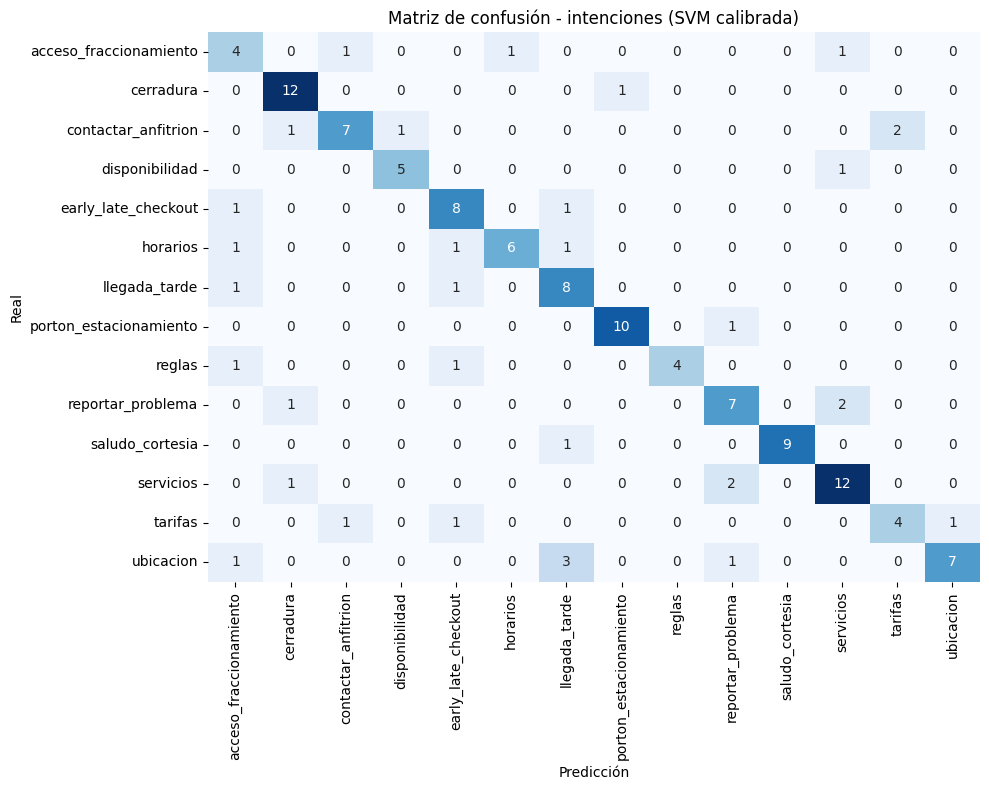

,texto,real,pred
366,cobran multa si hay danos,reglas,early_late_checkout
69,cobran extra por mascota,tarifas,early_late_checkout
21,hasta luego,saludo_cortesia,llegada_tarde
213,hay que registrarse en la entrada,acceso_fraccionamiento,horarios
399,entrada anticipada es posible?,early_late_checkout,acceso_fraccionamiento
451,me das el numero de la dueña,contactar_anfitrion,cerradura
64,que tan caro es,tarifas,ubicacion
410,hay una fuga en la cocina,reportar_problema,servicios
677,si reservamos seguido hay mejor precio,contactar_anfitrion,tarifas
650,hay descuento si reservo las 4 unidades,contactar_anfitrion,disponibilidad


In [6]:
clf_texto = make_pipeline(tfidf(), CalibratedClassifierCV(LinearSVC(C=0.5, random_state=SEED), cv=5))
clf_texto.fit(X_tr, y_tr)
pred_te = clf_texto.predict(X_te)
reporte_texto = classification_report(y_te, pred_te, zero_division=0, output_dict=True)
print(classification_report(y_te, pred_te, zero_division=0, digits=3))
etiquetas = sorted(corpus["intencion"].unique())
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_te, pred_te, labels=etiquetas), annot=True, fmt="d", cmap="Blues",
            xticklabels=etiquetas, yticklabels=etiquetas, cbar=False)
plt.title("Matriz de confusión - intenciones (SVM calibrada)"); plt.xlabel("Predicción"); plt.ylabel("Real")
plt.tight_layout(); plt.savefig("salidas/cm_texto.png", dpi=160); plt.show()
errores = pd.DataFrame({"texto": corpus.loc[X_te.index, "texto"], "real": y_te, "pred": pred_te})
errores = errores[errores.real != errores.pred]
errores.to_csv("salidas/errores_texto.csv", index=False)
errores

### Umbral de confianza: lo que el modelo no reconoce se escala a la anfitriona, no se adivina

In [7]:
UMBRAL = 0.40


def vectorizar(texto: str) -> pd.DataFrame:
    return pd.DataFrame({"norm": [preprocesar(texto, stem=False, quitar_stop=False)], "proc": [preprocesar(texto)]})


def clasificar_texto(texto: str):
    prob = clf_texto.predict_proba(vectorizar(texto))[0]
    i = int(np.argmax(prob))
    return clf_texto.classes_[i], float(prob[i])


conf_prueba = clf_texto.predict_proba(X_te).max(axis=1)
acierto = (pred_te == y_te.values)
conf_fuera = np.array([clasificar_texto(t)[1] for t in fuera["texto"]])
umbrales = pd.DataFrame([{"umbral": u, "cobertura": (conf_prueba >= u).mean(),
                          "accuracy_cubierta": acierto[conf_prueba >= u].mean(),
                          "fuera_de_alcance_escalado": (conf_fuera < u).mean()} for u in [0.2, 0.3, 0.4, 0.5]])
print(umbrales.round(3).to_string(index=False))
pd.DataFrame([(t, *clasificar_texto(t)) for t in fuera["texto"]], columns=["texto", "intencion", "confianza"]).round(2)

 umbral  cobertura  accuracy_cubierta  fuera_de_alcance_escalado
    0.2      0.993              0.750                      0.000
    0.3      0.927              0.764                      0.000
    0.4      0.832              0.816                      0.125
    0.5      0.664              0.879                      0.375


,texto,intencion,confianza
0,recomiendan algun restaurante por aca,servicios,0.55
1,que lugares hay para visitar,porton_estacionamiento,0.40
2,donde puedo comprar despensa cerca,ubicacion,0.53
3,saben si hay farmacia cerca,ubicacion,0.44
4,como esta el clima alla,reportar_problema,0.53
5,me pueden recomendar un taxi de confianza,contactar_anfitrion,0.34
6,hay gimnasio cerca,ubicacion,0.64
7,a que hora abre el super,horarios,0.75


In [8]:
fila = umbrales[umbrales.umbral == UMBRAL].iloc[0]
RESUMEN["texto"] = {"dimension_tfidf": int(dims), "modelos": res_texto.round(4).to_dict("records"),
                    "ablacion": ablacion.round(4).to_dict("records"),
                    "svm_calibrada": {"accuracy": accuracy_score(y_te, pred_te), "f1_macro": f1_score(y_te, pred_te, average="macro")},
                    "por_intencion": {k: v for k, v in reporte_texto.items() if k in etiquetas},
                    "n_prueba": len(y_te), "errores": errores.to_dict("records"),
                    "umbral": UMBRAL, "umbrales": umbrales.round(4).to_dict("records")}

## 4. Conjunto de imágenes
Cinco clases que corresponden a lo que un huésped fotografía cuando algo no le abre o no funciona:
`cerradura` (chapa electrónica), `porton` (portón del estacionamiento), `caseta` (acceso del fraccionamiento),
`controles` (minisplit, termostato, control remoto) e `interior` (recámara, sala, cocina).
Las imágenes son de Wikimedia Commons con licencia libre (créditos en `datos/creditos_imagenes.csv`), revisadas a mano.
Se quitan casi duplicados con un hash perceptual antes de dividir, para que la prueba no vea fotos "gemelas" del entrenamiento.

/Users/jphf/haru-work/tec-avance2/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Imágenes únicas: 256
cerradura    52
porton       49
caseta       45
controles    50
interior     60
Entrenamiento: 179 | Validación: 38 | Prueba: 39


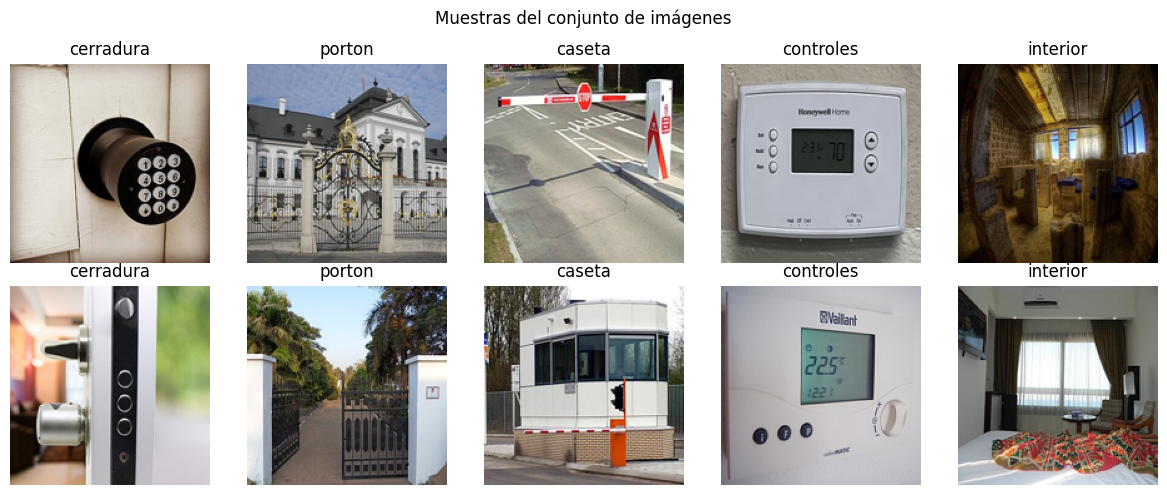

In [9]:
import glob
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.random.set_seed(SEED)
CLASES = ["cerradura", "porton", "caseta", "controles", "interior"]
TAM = 160


def ahash(ruta, n=8):
    im = Image.open(ruta).convert("L").resize((n, n))
    a = np.asarray(im, dtype=np.float32)
    return tuple((a > a.mean()).flatten())


rutas, etiquetas_img, vistos = [], [], {}
for k, c in enumerate(CLASES):
    for r in sorted(glob.glob(f"datos/imagenes/{c}/*.jpg")):
        h = ahash(r)
        if h in vistos:
            continue
        vistos[h] = r
        rutas.append(r); etiquetas_img.append(k)
rutas, etiquetas_img = np.array(rutas), np.array(etiquetas_img)
conteo_img = pd.Series([CLASES[i] for i in etiquetas_img]).value_counts().reindex(CLASES)
print("Imágenes únicas:", len(rutas)); print(conteo_img.to_string())

r_tr, r_tmp, e_tr, e_tmp = train_test_split(rutas, etiquetas_img, test_size=0.30, random_state=SEED, stratify=etiquetas_img)
r_va, r_te, e_va, e_te = train_test_split(r_tmp, e_tmp, test_size=0.50, random_state=SEED, stratify=e_tmp)
print("Entrenamiento:", len(r_tr), "| Validación:", len(r_va), "| Prueba:", len(r_te))


def cargar(rs):
    return np.stack([np.asarray(Image.open(r).convert("RGB").resize((TAM, TAM)), dtype=np.float32) for r in rs])


x_tr, x_va, x_te = cargar(r_tr), cargar(r_va), cargar(r_te)
y_tr_c, y_va_c = tf.keras.utils.to_categorical(e_tr, 5), tf.keras.utils.to_categorical(e_va, 5)

plt.figure(figsize=(12, 5))
for i, k in enumerate(range(5)):
    idx = np.where(e_tr == k)[0][:2]
    for j, ii in enumerate(idx):
        plt.subplot(2, 5, j * 5 + i + 1); plt.imshow(x_tr[ii].astype("uint8")); plt.title(CLASES[k]); plt.axis("off")
plt.suptitle("Muestras del conjunto de imágenes"); plt.tight_layout(); plt.savefig("salidas/muestras_imagenes.png", dpi=140); plt.show()

## 5. Clasificador visual
Igual que en la sesión del 12 de noviembre se comparan dos redes: una CNN entrenada desde cero y ResNet50
preentrenada en ImageNet con transferencia de aprendizaje. Ambas usan aumento de datos dentro del modelo
(volteo, rotación y zoom) y los mismos callbacks (EarlyStopping y ReduceLROnPlateau).

In [10]:
def aumento():
    return tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08),
                                layers.RandomZoom(0.10)], name="aumento_de_datos")


def callbacks(paciencia=4):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]


# CNN desde cero (misma arquitectura que la sesión, a 96x96). BatchNormalization con momentum 0.9:
# con ~6 lotes por época, el valor por defecto (0.99) no alcanza a estimar las estadísticas y la validación
# se queda plana en una sola clase (lo vimos en la primera corrida: 18 % constante).
ent = layers.Input(shape=(TAM, TAM, 3))
x = layers.Resizing(96, 96)(ent)
x = layers.Rescaling(1 / 255.0)(x)
x = aumento()(x)
for filtros, abandono in [(32, 0.25), (64, 0.30), (128, 0.40)]:
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.MaxPooling2D(2)(x); x = layers.Dropout(abandono)(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.5)(x)
cnn_model = models.Model(ent, layers.Dense(5, activation="softmax")(x), name="CNN_desde_cero")
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
hist_cnn = cnn_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=40, batch_size=32,
                         callbacks=callbacks(paciencia=10), verbose=2)  # más paciencia: entrena desde cero

Epoch 1/40


6/6 - 5s - 862ms/step - accuracy: 0.2793 - loss: 1.9099 - val_accuracy: 0.1842 - val_loss: 1.6973 - learning_rate: 0.0010


Epoch 2/40


6/6 - 3s - 435ms/step - accuracy: 0.4749 - loss: 1.3745 - val_accuracy: 0.1842 - val_loss: 2.1258 - learning_rate: 0.0010


Epoch 3/40


6/6 - 3s - 485ms/step - accuracy: 0.5307 - loss: 1.2191 - val_accuracy: 0.1842 - val_loss: 2.3039 - learning_rate: 0.0010


... (32 outputs left out)

Epoch 20/40


6/6 - 3s - 480ms/step - accuracy: 0.7821 - loss: 0.6393 - val_accuracy: 0.5263 - val_loss: 1.2438 - learning_rate: 1.5625e-05


Epoch 21/40


6/6 - 3s - 478ms/step - accuracy: 0.7709 - loss: 0.7054 - val_accuracy: 0.5000 - val_loss: 1.2505 - learning_rate: 1.5625e-05


In [11]:
# ResNet50 con transferencia: base congelada, solo se entrena la cabeza de clasificación
base = ResNet50(weights="imagenet", include_top=False, input_shape=(TAM, TAM, 3))
base.trainable = False
ent = layers.Input(shape=(TAM, TAM, 3))
r = aumento()(ent)
r = layers.Lambda(preprocess_input, name="preprocesar_resnet")(r)
r = base(r, training=False)
r = layers.GlobalAveragePooling2D()(r)
r = layers.Dropout(0.40)(r)
resnet_model = models.Model(ent, layers.Dense(5, activation="softmax")(r), name="ResNet50_transferencia")
resnet_model.compile(optimizer=tf.keras.optimizers.Adam(5e-4), loss="categorical_crossentropy", metrics=["accuracy"])
print("Parámetros entrenables:", sum(int(np.prod(w.shape)) for w in resnet_model.trainable_weights),
      "de", resnet_model.count_params())
hist_res = resnet_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=15, batch_size=16,
                            callbacks=callbacks(), verbose=2)

Parámetros entrenables: 10245 de 23597957
Epoch 1/15


12/12 - 8s - 647ms/step - accuracy: 0.2682 - loss: 2.2474 - val_accuracy: 0.4211 - val_loss: 1.1381 - learning_rate: 5.0000e-04


Epoch 2/15


12/12 - 4s - 362ms/step - accuracy: 0.5475 - loss: 1.1852 - val_accuracy: 0.7895 - val_loss: 0.6966 - learning_rate: 5.0000e-04


Epoch 3/15


12/12 - 4s - 353ms/step - accuracy: 0.6536 - loss: 0.8869 - val_accuracy: 0.8421 - val_loss: 0.4499 - learning_rate: 5.0000e-04


... (16 outputs left out)

Epoch 12/15


12/12 - 4s - 357ms/step - accuracy: 0.9106 - loss: 0.2179 - val_accuracy: 0.8947 - val_loss: 0.3504 - learning_rate: 2.5000e-04


Epoch 13/15


12/12 - 4s - 374ms/step - accuracy: 0.9385 - loss: 0.2063 - val_accuracy: 0.8947 - val_loss: 0.3397 - learning_rate: 2.5000e-04


In [12]:
# Ajuste fino: se descongela el último bloque (conv5) con una tasa de aprendizaje baja
base.trainable = True
for capa in base.layers:
    capa.trainable = capa.name.startswith("conv5") and not isinstance(capa, layers.BatchNormalization)
resnet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
hist_ft = resnet_model.fit(x_tr, y_tr_c, validation_data=(x_va, y_va_c), epochs=6, batch_size=16,
                           callbacks=callbacks(), verbose=2)

Epoch 1/6


12/12 - 10s - 873ms/step - accuracy: 0.9330 - loss: 0.2401 - val_accuracy: 0.9474 - val_loss: 0.3319 - learning_rate: 1.0000e-05


Epoch 2/6


12/12 - 6s - 513ms/step - accuracy: 0.9497 - loss: 0.1292 - val_accuracy: 0.9211 - val_loss: 0.3481 - learning_rate: 1.0000e-05


Epoch 3/6


12/12 - 6s - 518ms/step - accuracy: 0.9777 - loss: 0.0991 - val_accuracy: 0.9474 - val_loss: 0.3230 - learning_rate: 1.0000e-05


... (2 outputs left out)

Epoch 5/6


12/12 - 6s - 523ms/step - accuracy: 0.9888 - loss: 0.0663 - val_accuracy: 0.9211 - val_loss: 0.3139 - learning_rate: 1.0000e-05


Epoch 6/6


12/12 - 7s - 575ms/step - accuracy: 0.9721 - loss: 0.0726 - val_accuracy: 0.9211 - val_loss: 0.3365 - learning_rate: 1.0000e-05


## 6. Evaluación del clasificador visual (conjunto de prueba, nunca visto en el entrenamiento)

                                modelo  accuracy  precision_macro  recall_macro  f1_macro
                        CNN desde cero     0.538            0.535         0.550     0.527
ResNet50 (transferencia + ajuste fino)     0.872            0.899         0.867     0.876
              precision    recall  f1-score   support

   cerradura      0.636     0.875     0.737         8
      porton      1.000     0.875     0.933         8
      caseta      1.000     0.833     0.909         6
   controles      0.857     0.750     0.800         8
    interior      1.000     1.000     1.000         9

    accuracy                          0.872        39
   macro avg      0.899     0.867     0.876        39
weighted avg      0.896     0.872     0.877        39



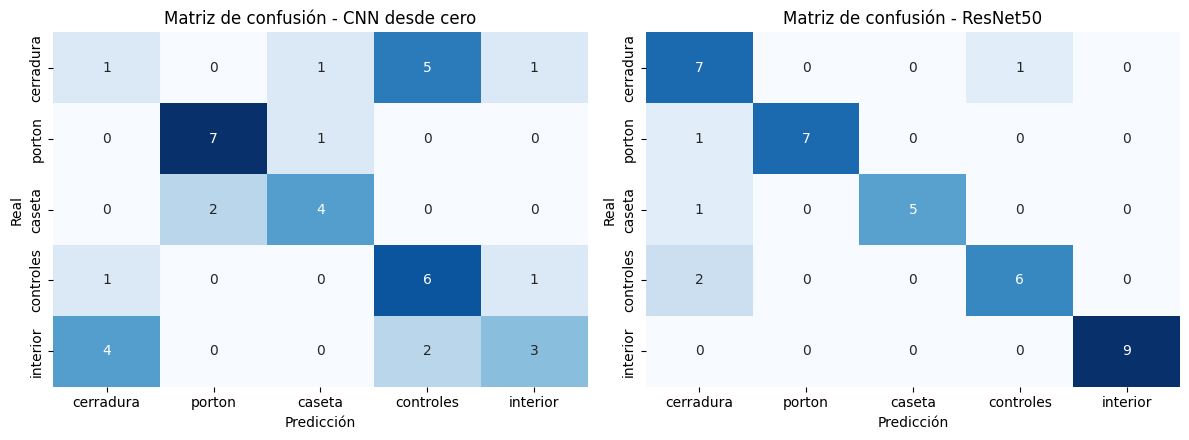

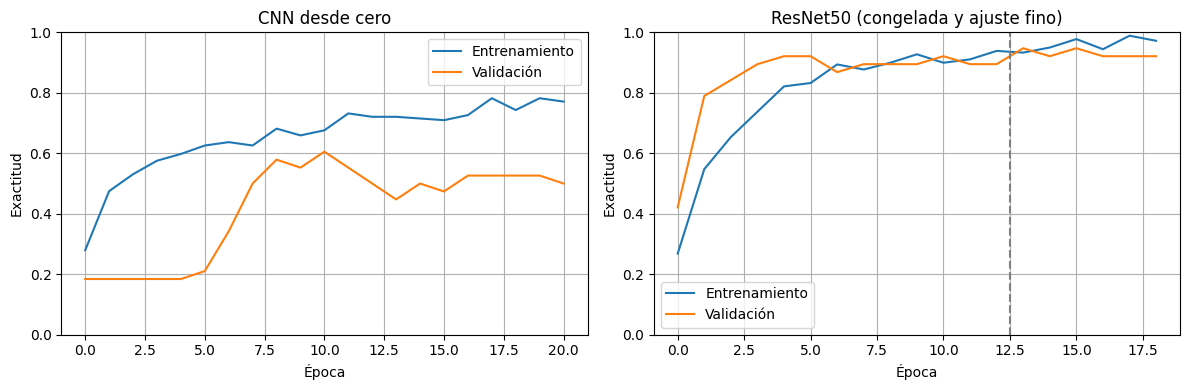

In [13]:
def evaluar(modelo, nombre):
    prob = modelo.predict(x_te, verbose=0)
    pred = prob.argmax(1)
    p, r_, f, _ = precision_recall_fscore_support(e_te, pred, average="macro", zero_division=0)
    return {"modelo": nombre, "accuracy": accuracy_score(e_te, pred), "precision_macro": p,
            "recall_macro": r_, "f1_macro": f}, pred, prob


res_cnn, pred_cnn, _ = evaluar(cnn_model, "CNN desde cero")
res_res, pred_res, prob_res = evaluar(resnet_model, "ResNet50 (transferencia + ajuste fino)")
res_vision = pd.DataFrame([res_cnn, res_res])
print(res_vision.round(3).to_string(index=False))
print(classification_report(e_te, pred_res, target_names=CLASES, digits=3, zero_division=0))
reporte_vision = classification_report(e_te, pred_res, target_names=CLASES, output_dict=True, zero_division=0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pr, t in [(ejes[0], pred_cnn, "CNN desde cero"), (ejes[1], pred_res, "ResNet50")]:
    sns.heatmap(confusion_matrix(e_te, pr, labels=range(5)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_title("Matriz de confusión - " + t); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.savefig("salidas/cm_vision.png", dpi=160); plt.show()

hist_total = {k: hist_res.history[k] + hist_ft.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, h, t in [(ejes[0], hist_cnn.history, "CNN desde cero"), (ejes[1], hist_total, "ResNet50 (congelada y ajuste fino)")]:
    ax.plot(h["accuracy"], label="Entrenamiento"); ax.plot(h["val_accuracy"], label="Validación")
    ax.set_title(t); ax.set_xlabel("Época"); ax.set_ylabel("Exactitud"); ax.set_ylim(0, 1); ax.grid(True); ax.legend()
ejes[1].axvline(len(hist_res.history["loss"]) - 0.5, ls="--", c="gray")
plt.tight_layout(); plt.savefig("salidas/curvas_vision.png", dpi=140); plt.show()

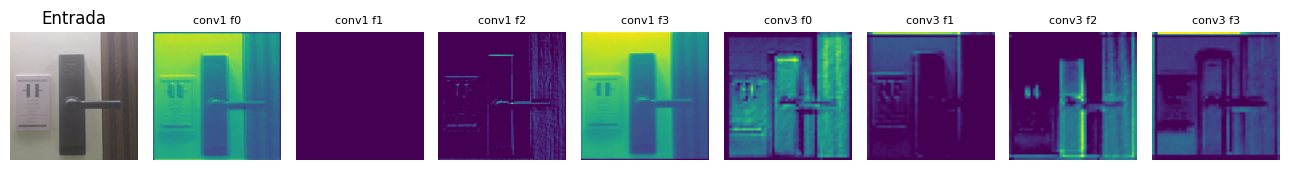

In [14]:
# Mapas de activación de la CNN desde cero (como en la sesión): qué patrones detectan las primeras convoluciones
capas_conv = [c for c in cnn_model.layers if isinstance(c, layers.Conv2D)]
modelo_act = models.Model(cnn_model.inputs, [c.output for c in capas_conv[:3:2]])
i_ej = int(np.where(e_te == 0)[0][0])
mapas = modelo_act.predict(x_te[i_ej:i_ej + 1], verbose=0)
fig = plt.figure(figsize=(13, 1.9))
plt.subplot(1, 9, 1); plt.imshow(x_te[i_ej].astype("uint8")); plt.title("Entrada"); plt.axis("off")
for j in range(8):
    m = mapas[j // 4][0, :, :, j % 4]
    plt.subplot(1, 9, j + 2); plt.imshow(m, cmap="viridis"); plt.axis("off")
    plt.title(f"{'conv1' if j < 4 else 'conv3'} f{j % 4}", fontsize=8)
plt.tight_layout(); plt.savefig("salidas/activaciones.png", dpi=140); plt.show()

RESUMEN["vision"] = {"conteo": conteo_img.to_dict(), "n_train": len(r_tr), "n_val": len(r_va), "n_test": len(r_te),
                     "modelos": res_vision.round(4).to_dict("records"),
                     "por_clase": {k: v for k, v in reporte_vision.items() if k in CLASES},
                     "epocas": {"cnn": len(hist_cnn.history["loss"]), "resnet": len(hist_res.history["loss"]),
                                "ajuste_fino": len(hist_ft.history["loss"])}}
resnet_model.save("salidas/resnet50_hospedaje.keras")

## 7. Integración multimodal texto-imagen
1) El clasificador de intenciones etiqueta el texto. 2) ResNet50 etiqueta la foto. 3) Una política de decisión
combina ambas etiquetas y responde con la base de conocimiento del Avance 1 o escala a la anfitriona.
Regla clave: si el texto es ambiguo ("no me abre") la foto decide de qué acceso se trata.

In [15]:
BASE = {  # datos sintéticos del Avance 1 (Casa Almendro)
    "cerradura": "La puerta tiene cerradura electrónica: marca el código de 4 dígitos que te enviamos el día de llegada y presiona la palomita. Si parpadea en rojo, espera 1 minuto y vuelve a intentar.",
    "porton_estacionamiento": "El portón del estacionamiento se abre con el control que está en la caja junto a la entrada principal. Si no responde, presiona el botón 2 segundos frente al motor.",
    "acceso_fraccionamiento": "En la caseta indica que vas a Casa Almendro, lote 12, y muestra tu identificación. El guardia registra tu placa.",
    "reportar_problema": "Gracias por avisar. Revisa que el control del minisplit tenga pilas y esté en modo frío (copo de nieve). Si sigue sin funcionar, la anfitriona te contacta en breve.",
    "llegada_tarde": "Sí, puedes llegar tarde sin problema: el acceso es con código y no necesitas que alguien te reciba.",
    "horarios": "Check-in desde las 15:00 y check-out a las 11:00.",
    "ubicacion": "Fraccionamiento Las Palmas (ficticio), Calle Ejemplo 123, a 10 minutos del centro.",
}
ESCALAR = {"early_late_checkout", "contactar_anfitrion"}
ACCESO = {"cerradura", "porton_estacionamiento", "acceso_fraccionamiento"}
IMAGEN_A_INTENCION = {"cerradura": "cerradura", "porton": "porton_estacionamiento", "caseta": "acceso_fraccionamiento",
                      "controles": "reportar_problema", "interior": "reportar_problema"}
UMBRAL_IMG = 0.60
TEXTO_AMBIGUO = 0.60  # con foto confiable, un texto por debajo de esto deja decidir a la imagen


def clasificar_imagen(arr):
    prob = resnet_model.predict(arr[None, ...], verbose=0)[0]
    return CLASES[int(prob.argmax())], float(prob.max())


def atender(texto, imagen=None):
    intencion, p = clasificar_texto(texto)
    clase, q = clasificar_imagen(imagen) if imagen is not None else (None, 0.0)
    final, motivo = intencion, "texto"
    if clase and q >= UMBRAL_IMG:
        sugerida = IMAGEN_A_INTENCION[clase]
        if p < TEXTO_AMBIGUO or (intencion in ACCESO and sugerida in ACCESO) or intencion == "reportar_problema":
            final, motivo = sugerida, ("imagen" if sugerida != intencion else "texto e imagen coinciden")
    if final in ESCALAR or (p < UMBRAL and (clase is None or q < UMBRAL_IMG)):
        accion, respuesta = "ESCALAR", "Le paso tu mensaje a la anfitriona" + (f" con la foto ({clase})." if clase else ".")
    elif final == "reportar_problema" and clase == "interior":
        accion, respuesta = "ESCALAR", "Gracias por la foto. Le aviso a la anfitriona para que lo revise contigo."
    else:
        accion, respuesta = "RESPONDER", BASE.get(final, "Con gusto te ayudo; la anfitriona te confirma este dato.")
    return {"texto": texto, "intencion": intencion, "conf_texto": round(p, 2), "imagen": clase,
            "conf_imagen": round(q, 2), "decision_por": motivo, "intencion_final": final, "accion": accion,
            "respuesta": respuesta}


def foto_de(clase, n=0):
    return x_te[np.where(e_te == CLASES.index(clase))[0][n]]


casos = [("no me abre", "cerradura"), ("no me abre", "porton"), ("ya estoy aqui y no puedo pasar", "caseta"),
         ("hace mucho calor y no enfria", "controles"), ("mira como esta esto", "interior"),
         ("me puedo quedar mas tarde el domingo", None), ("a que hora es el check in", None),
         ("recomiendan algun restaurante por aca", None)]
salida = pd.DataFrame([atender(t, foto_de(c) if c else None) for t, c in casos])
salida.to_csv("salidas/integracion.csv", index=False)
RESUMEN["integracion"] = salida.to_dict("records")
salida[["texto", "intencion", "conf_texto", "imagen", "conf_imagen", "decision_por", "accion", "respuesta"]]

,texto,intencion,conf_texto,imagen,conf_imagen,decision_por,accion,respuesta
0,no me abre,cerradura,0.70,cerradura,1.00,texto e imagen coinciden,RESPONDER,La puerta tiene cerradura electrónica: marca e...
1,no me abre,cerradura,0.70,porton,1.00,imagen,RESPONDER,El portón del estacionamiento se abre con el c...
2,ya estoy aqui y no puedo pasar,reglas,0.15,caseta,1.00,imagen,RESPONDER,"En la caseta indica que vas a Casa Almendro, l..."
3,hace mucho calor y no enfria,reportar_problema,0.72,controles,0.96,texto e imagen coinciden,RESPONDER,Gracias por avisar. Revisa que el control del ...
4,mira como esta esto,ubicacion,0.40,interior,1.00,imagen,ESCALAR,Gracias por la foto. Le aviso a la anfitriona ...
5,me puedo quedar mas tarde el domingo,early_late_checkout,0.79,None,0.00,texto,ESCALAR,Le paso tu mensaje a la anfitriona.
6,a que hora es el check in,horarios,0.87,None,0.00,texto,RESPONDER,Check-in desde las 15:00 y check-out a las 11:00.
7,recomiendan algun restaurante por aca,servicios,0.55,None,0.00,texto,RESPONDER,Con gusto te ayudo; la anfitriona te confirma ...


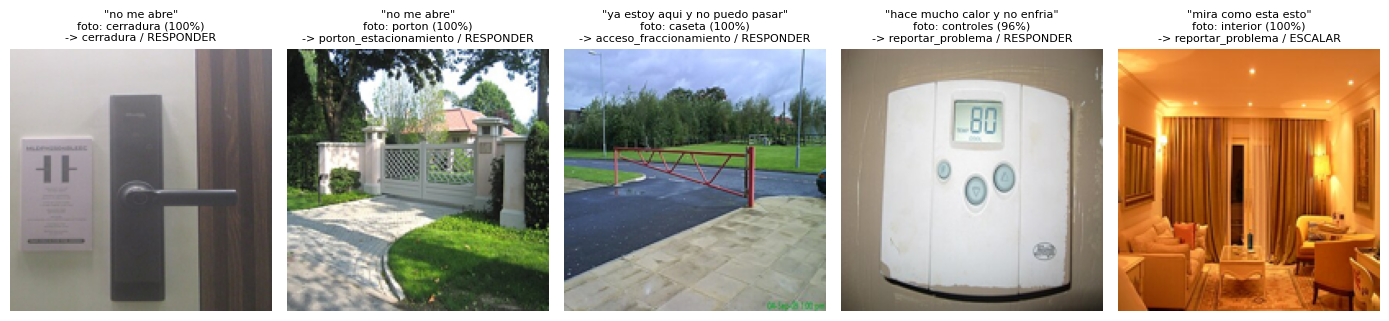

Listo: salidas/resumen.json


In [16]:
fig = plt.figure(figsize=(14, 3.6))
for i, (t, c) in enumerate(casos[:5]):
    s = salida.iloc[i]
    plt.subplot(1, 5, i + 1); plt.imshow(foto_de(c).astype("uint8")); plt.axis("off")
    plt.title(f"\"{t}\"\nfoto: {s.imagen} ({s.conf_imagen:.0%})\n-> {s.intencion_final} / {s.accion}", fontsize=8)
plt.tight_layout(); plt.savefig("salidas/integracion.png", dpi=150); plt.show()

with open("salidas/resumen.json", "w") as f:
    json.dump(RESUMEN, f, ensure_ascii=False, indent=1, default=float)
print("Listo: salidas/resumen.json")